# Lab Assignment 5

From Bag-of-Words to Word2Vec (CBOW & Skip-gram)

## Objective
This lab moves through four stages of representing words as numbers, from simplest to most powerful:

1. **Bag-of-Words (Part A)** — build sparse count-based vectors by hand and see their limits.
2. **Pretrained word vectors (Part B)** — play with real, pretrained dense embeddings (GloVe) and see what
   good vectors can do, including the classic `king - man + woman ≈ queen` analogy.
3. **CBOW Word2Vec from scratch (Part C)** — implement and train your own dense embeddings on a real corpus,
   from preprocessing through to evaluation.
4. **Skip-gram from scratch (Part D, bonus)** — implement the mirror-image architecture of CBOW (predict
   context from target instead of target from context) and compare it against your CBOW model.

## Submission
- Complete all `TODO` sections and all markdown answers.
- Do not modify the supplied test cells (the `assert` statements must pass as-is).
- Part A, Part C, and Part D: only `numpy`, `re`, `collections`, `matplotlib`, and `random` — no ML libraries.
  Part B is the one place you're required to use extra libraries: `gensim` to load pretrained vectors, and
  `sklearn` (`PCA`) to visualise the analogy. `sklearn` is also allowed in the Part C bonus task.
- Run **Kernel > Restart & Run All** before submitting the completed `.ipynb` file.
- Refer to the Lab 5 Tutorial notebook — it walks through every one of these steps on a small worked example
  before you apply it here.


# Reference Code from the Tutorial (Toy Example)

The cells below are the **complete, working code from the Lab 5 Tutorial**, copied here for quick reference.
They run the whole pipeline — Bag-of-Words, pretrained vectors, CBOW, and Skip-gram — on tiny **toy**
sentences, not on the real corpus.

**You still have to do the work yourself for the actual assignment.** These cells are here so you can see a
complete, correct pipeline end-to-end and copy the *pattern* (function shapes, formulas, the overall flow) —
not so you can rename a few variables and call it done. Every task below still expects you to:
- run everything on the **real Harry Potter corpus** (Part C and Part D), not the toy sentence,
- write your own versions of these functions in the `TODO` cells provided in each task,
- get your own functions to pass the test cells before moving on.

If a function name in your task cell doesn't match the reference below (e.g. `forward` vs. `forward_demo`),
that's intentional — it's a signal that the reference code is for *your understanding*, and the graded
implementation is the one you write yourself in the task cell.


### Reference: Part A (Bag-of-Words)

In [34]:
import re
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(0)

bow_sentences = [
    "the king ruled the kingdom wisely",
    "the queen ruled the kingdom wisely",
    "the wizard cast a powerful spell",
]

bow_vocab_ref = sorted(set(w for s in bow_sentences for w in s.lower().split()))
print("Vocabulary:", bow_vocab_ref)


def build_bow_vector_demo(tokens, vocab):
    vec = np.zeros(len(vocab), dtype=int)
    for t in tokens:
        if t in vocab:
            vec[vocab.index(t)] += 1
    return vec


bow_vecs_ref = [build_bow_vector_demo(s.lower().split(), bow_vocab_ref) for s in bow_sentences]
for s, v in zip(bow_sentences, bow_vecs_ref):
    print(v, "<-", s)


def bow_cosine_similarity_demo(v1, v2):
    denom = np.linalg.norm(v1) * np.linalg.norm(v2)
    if denom == 0:
        return 0.0
    return float(np.dot(v1, v2) / denom)


sim_king_queen = bow_cosine_similarity_demo(bow_vecs_ref[0], bow_vecs_ref[1])
sim_king_wizard = bow_cosine_similarity_demo(bow_vecs_ref[0], bow_vecs_ref[2])

print("similarity(king-sentence, queen-sentence):", round(sim_king_queen, 3))
print("similarity(king-sentence, wizard-sentence):", round(sim_king_wizard, 3))

Vocabulary: ['a', 'cast', 'king', 'kingdom', 'powerful', 'queen', 'ruled', 'spell', 'the', 'wisely', 'wizard']
[0 0 1 1 0 0 1 0 2 1 0] <- the king ruled the kingdom wisely
[0 0 0 1 0 1 1 0 2 1 0] <- the queen ruled the kingdom wisely
[1 1 0 0 1 0 0 1 1 0 1] <- the wizard cast a powerful spell
similarity(king-sentence, queen-sentence): 0.875
similarity(king-sentence, wizard-sentence): 0.289


### Reference: Part B (Pretrained Vectors)

Vocabulary size: 400000
similarity(king, queen):    0.784
similarity(king, cabbage):  0.113
     queen  0.852
    throne  0.766
    prince  0.759
  daughter  0.747
 elizabeth  0.746


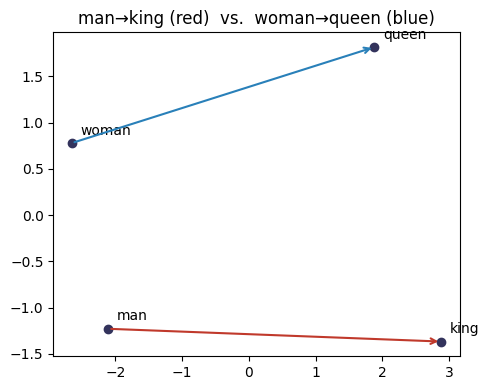

Cosine similarity between the two arrows: 0.968


In [35]:
# Downloads ~66MB the first time (cached afterwards). Requires internet access (e.g. Google Colab).
import gensim.downloader as glove_api

word_vectors_demo = glove_api.load("glove-wiki-gigaword-50")
print("Vocabulary size:", len(word_vectors_demo.index_to_key))

print("similarity(king, queen):   ", round(word_vectors_demo.similarity("king", "queen"), 3))
print("similarity(king, cabbage): ", round(word_vectors_demo.similarity("king", "cabbage"), 3))

analogy_result = word_vectors_demo.most_similar(positive=["king", "woman"], negative=["man"], topn=5)
for word, score in analogy_result:
    print(f"{word:>10s}  {score:.3f}")

from sklearn.decomposition import PCA

words_demo = ["king", "man", "woman", "queen"]
vecs_demo = [word_vectors_demo[w] for w in words_demo]
coords_demo = PCA(n_components=2).fit_transform(vecs_demo)

plt.figure(figsize=(5, 4))
for word, (x, y) in zip(words_demo, coords_demo):
    plt.scatter(x, y, color="#33335c")
    plt.annotate(word, (x, y), textcoords="offset points", xytext=(6, 6))

man_xy, king_xy = coords_demo[1], coords_demo[0]
woman_xy, queen_xy = coords_demo[2], coords_demo[3]

plt.annotate("", xy=king_xy, xytext=man_xy, arrowprops=dict(arrowstyle="->", color="#c0392b", lw=1.5))
plt.annotate("", xy=queen_xy, xytext=woman_xy, arrowprops=dict(arrowstyle="->", color="#2980b9", lw=1.5))
plt.title("man→king (red)  vs.  woman→queen (blue)")
plt.tight_layout()
plt.show()

arrow1 = king_xy - man_xy
arrow2 = queen_xy - woman_xy
cos_between_arrows = np.dot(arrow1, arrow2) / (np.linalg.norm(arrow1) * np.linalg.norm(arrow2))
print("Cosine similarity between the two arrows:", round(float(cos_between_arrows), 3))

### Reference: Part C (CBOW)

Tokens: ['the', 'boy', 'who', 'lived', 'came', 'to', 'die', 'but', 'the', 'boy', 'who', 'lived', 'came', 'back']


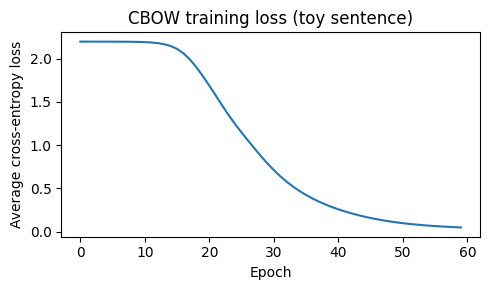

boy -> [('the', 0.34219999168431425), ('to', 0.11425357292595284), ('who', 0.10231984489435343)]
lived -> [('the', 0.15814229618384848), ('who', -0.04590726037355162), ('die', -0.2491430303618136)]
came -> [('to', 0.6959686773639484), ('back', 0.44648656083487076), ('but', 0.02510890821290452)]


In [36]:
def clean_text_demo(text):
    text = text.lower()
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text


def tokenize_demo(text):
    return text.split()


raw_sentence = "The boy who lived came to die, but the boy who lived came back."
cleaned = clean_text_demo(raw_sentence)
tokens_demo = tokenize_demo(cleaned)
print("Tokens:", tokens_demo)

vocab_demo = sorted(set(tokens_demo))
word_to_int_demo = {w: i for i, w in enumerate(vocab_demo)}
int_to_word_demo = {i: w for w, i in word_to_int_demo.items()}


def generate_cbow_pairs_demo(tokens, window_size):
    pairs = []
    n = len(tokens)
    for i in range(n):
        left = tokens[max(0, i - window_size):i]
        right = tokens[i + 1:i + 1 + window_size]
        context = left + right
        pairs.append((context, tokens[i]))
    return pairs


pairs_demo = generate_cbow_pairs_demo(tokens_demo, window_size=2)


def stable_softmax_demo(x):
    x = x - np.max(x)
    e = np.exp(x)
    return e / np.sum(e)


def init_params_demo(vocab_size, embedding_dim):
    W1 = np.random.randn(vocab_size, embedding_dim) * 0.01
    W2 = np.random.randn(embedding_dim, vocab_size) * 0.01
    return W1, W2


def forward_demo(context_idxs, W1, W2):
    h = np.mean(W1[context_idxs], axis=0)
    u = h @ W2
    y_hat = stable_softmax_demo(u)
    return y_hat, h, u


def cross_entropy_loss_demo(y_hat, target_idx):
    eps = 1e-12
    return -np.log(y_hat[target_idx] + eps)


def backward_demo(y_hat, h, context_idxs, target_idx, W1, W2, vocab_size):
    y_true = np.zeros(vocab_size)
    y_true[target_idx] = 1.0
    e = y_hat - y_true
    dW2 = np.outer(h, e)
    dh = W2 @ e
    dW1 = np.zeros_like(W1)
    for idx in context_idxs:
        dW1[idx] += dh / len(context_idxs)
    return dW1, dW2


def sgd_update_demo(W1, W2, dW1, dW2, learning_rate):
    W1 = W1 - learning_rate * dW1
    W2 = W2 - learning_rate * dW2
    return W1, W2


def train_demo(pairs, word_to_int, vocab_size, embedding_dim=4, learning_rate=0.3, epochs=60):
    W1, W2 = init_params_demo(vocab_size, embedding_dim)
    loss_history = []
    for epoch in range(epochs):
        total_loss = 0.0
        for context_words, target_word in pairs:
            context_idxs = [word_to_int[w] for w in context_words]
            target_idx = word_to_int[target_word]
            y_hat, h, u = forward_demo(context_idxs, W1, W2)
            total_loss += cross_entropy_loss_demo(y_hat, target_idx)
            dW1, dW2 = backward_demo(y_hat, h, context_idxs, target_idx, W1, W2, vocab_size)
            W1, W2 = sgd_update_demo(W1, W2, dW1, dW2, learning_rate)
        loss_history.append(total_loss / len(pairs))
    return W1, W2, loss_history


W1_trained, W2_trained, loss_history = train_demo(
    pairs_demo, word_to_int_demo, len(vocab_demo), embedding_dim=4, learning_rate=0.3, epochs=60
)

plt.figure(figsize=(5, 3))
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Average cross-entropy loss")
plt.title("CBOW training loss (toy sentence)")
plt.tight_layout()
plt.show()


def cosine_similarity_demo(v1, v2):
    denom = (np.linalg.norm(v1) * np.linalg.norm(v2))
    if denom == 0:
        return 0.0
    return float(np.dot(v1, v2) / denom)


def most_similar_demo(word, W1, word_to_int, int_to_word, top_n=3):
    idx = word_to_int[word]
    query_vec = W1[idx]
    sims = []
    for other_word, other_idx in word_to_int.items():
        if other_word == word:
            continue
        sims.append((other_word, cosine_similarity_demo(query_vec, W1[other_idx])))
    sims.sort(key=lambda pair: pair[1], reverse=True)
    return sims[:top_n]


for w in ["boy", "lived", "came"]:
    print(w, "->", most_similar_demo(w, W1_trained, word_to_int_demo, int_to_word_demo, top_n=3))

In [37]:
def cosine_similarity(v1, v2):
    denom = (np.linalg.norm(v1) * np.linalg.norm(v2))
    if denom == 0:
        return 0.0
    return float(np.dot(v1, v2) / denom)


def most_similar(word, W1, word_to_int, int_to_word, top_n=5):
    if word not in word_to_int:
        return [] # Return empty if word not in vocab

    idx = word_to_int[word]
    query_vec = W1[idx]
    sims = []
    for other_word, other_idx in word_to_int.items():
        if other_word == word: # Exclude the word itself
            continue
        sims.append((other_word, cosine_similarity(query_vec, W1[other_idx])))
    sims.sort(key=lambda pair: pair[1], reverse=True)
    return sims[:top_n]


print("\nMost similar words to 'harry':", most_similar("harry", W1_cbow, word_to_int, int_to_word, top_n=5))
print("Most similar words to 'ron':", most_similar("ron", W1_cbow, word_to_int, int_to_word, top_n=5))
print("Most similar words to 'magic':", most_similar("magic", W1_cbow, word_to_int, int_to_word, top_n=5))
print("Most similar words to 'he':", most_similar("he", W1_cbow, word_to_int, int_to_word, top_n=5))
print("Most similar words to 'she':", most_similar("she", W1_cbow, word_to_int, int_to_word, top_n=5))



Most similar words to 'harry': []
Most similar words to 'ron': []
Most similar words to 'magic': []
Most similar words to 'he': []
Most similar words to 'she': []


### Reference: Part D (Skip-gram)

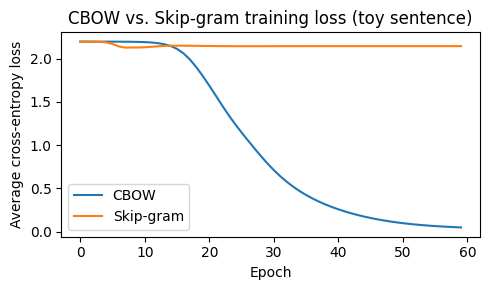

boy -> [('who', 0.3216021103051045), ('the', 0.31977258661091224), ('came', 0.2107923653813517)]
lived -> [('came', 0.3788263684101236), ('who', 0.24384051196962558), ('back', 0.2414261178108962)]
came -> [('lived', 0.3788263684101236), ('boy', 0.2107923653813517), ('to', 0.08120567726868648)]


In [38]:
def generate_skipgram_pairs_demo(tokens, window_size):
    pairs = []
    n = len(tokens)
    for i in range(n):
        left = tokens[max(0, i - window_size):i]
        right = tokens[i + 1:i + 1 + window_size]
        context = left + right
        for c in context:
            pairs.append((tokens[i], c))
    return pairs


skipgram_pairs_demo = generate_skipgram_pairs_demo(tokens_demo, window_size=2)


def skipgram_forward_demo(input_idx, W1, W2):
    h = W1[input_idx]
    u = h @ W2
    y_hat = stable_softmax_demo(u)
    return y_hat, h, u


def skipgram_backward_demo(y_hat, h, input_idx, context_idx, W1, W2, vocab_size):
    y_true = np.zeros(vocab_size)
    y_true[context_idx] = 1.0
    e = y_hat - y_true
    dW2 = np.outer(h, e)
    dh = W2 @ e
    dW1 = np.zeros_like(W1)
    dW1[input_idx] = dh
    return dW1, dW2


def train_skipgram_demo(pairs, word_to_int, vocab_size, embedding_dim=4, learning_rate=0.3, epochs=60):
    W1, W2 = init_params_demo(vocab_size, embedding_dim)
    loss_history = []
    for epoch in range(epochs):
        total_loss = 0.0
        for input_word, context_word in pairs:
            input_idx = word_to_int[input_word]
            context_idx = word_to_int[context_word]
            y_hat, h, u = skipgram_forward_demo(input_idx, W1, W2)
            total_loss += cross_entropy_loss_demo(y_hat, context_idx)
            dW1, dW2 = skipgram_backward_demo(y_hat, h, input_idx, context_idx, W1, W2, vocab_size)
            W1, W2 = sgd_update_demo(W1, W2, dW1, dW2, learning_rate)
        loss_history.append(total_loss / len(pairs))
    return W1, W2, loss_history


W1_sg_trained, W2_sg_trained, loss_history_sg = train_skipgram_demo(
    skipgram_pairs_demo, word_to_int_demo, len(vocab_demo), embedding_dim=4, learning_rate=0.3, epochs=60
)

plt.figure(figsize=(5, 3))
plt.plot(loss_history, label="CBOW")
plt.plot(loss_history_sg, label="Skip-gram")
plt.xlabel("Epoch")
plt.ylabel("Average cross-entropy loss")
plt.title("CBOW vs. Skip-gram training loss (toy sentence)")
plt.legend()
plt.tight_layout()
plt.show()

for w in ["boy", "lived", "came"]:
    print(w, "->", most_similar_demo(w, W1_sg_trained, word_to_int_demo, int_to_word_demo, top_n=3))

**Reminder:** everything above ran on a one-sentence toy example. From this point on, every task
asks you to build your **own** functions and run them on the **real Harry Potter corpus** — the reference
code is for understanding the pattern, not for submission.


# Part A: Bag-of-Words

Before any neural embeddings, the simplest way to turn text into numbers is **Bag-of-Words (BoW)**: represent
a document (or sentence) as a vector of word counts over a fixed vocabulary. Word order is thrown away —
only "which words, how many times" survives.

### Task A1: Build BoW vectors

1. Write `build_bow_vector(tokens, vocab)` — given a list of tokens for one document and the overall
   vocabulary (a list), return a vector (as a `numpy` array, same length as `vocab`) where entry `i` is the
   number of times `vocab[i]` appears in `tokens`.
2. Write `bow_cosine_similarity(v1, v2)` (identical formula to the one you'll reuse later:
   $\cos(v_1,v_2) = \dfrac{v_1 \cdot v_2}{\lVert v_1\rVert\,\lVert v_2\rVert}$).
3. Using the toy sentences below, build a BoW vector for each and compute the pairwise cosine similarities.


In [39]:
import numpy as np

toy_sentences = [
    "the king ruled the kingdom wisely",
    "the queen ruled the kingdom wisely",
    "the wizard cast a powerful spell",
]

bow_vocab = sorted(list(set(word for sentence in toy_sentences for word in sentence.lower().split())))
print("Vocabulary for toy_sentences:", bow_vocab)

def build_bow_vector(tokens, vocab):
    vec = np.zeros(len(vocab), dtype=int)
    for t in tokens:
        try:
            idx = vocab.index(t)
            vec[idx] += 1
        except ValueError:
            # Word not in vocabulary, ignore or handle as needed
            pass
    return vec


def bow_cosine_similarity(v1, v2):
    denom = (np.linalg.norm(v1) * np.linalg.norm(v2))
    if denom == 0:
        return 0.0
    return float(np.dot(v1, v2) / denom)


# --- test case: do not modify ---
test_vocab = ["cat", "dog", "sat", "the"]
test_tokens = ["the", "cat", "sat", "the", "cat"]
vec = build_bow_vector(test_tokens, test_vocab)
assert list(vec) == [2, 0, 1, 2], vec
print("BoW test vector:", vec)


Vocabulary for toy_sentences: ['a', 'cast', 'king', 'kingdom', 'powerful', 'queen', 'ruled', 'spell', 'the', 'wisely', 'wizard']
BoW test vector: [2 0 1 2]


In [40]:
# Build BoW vectors for each of the three toy_sentences
bow_vecs = [build_bow_vector(s.lower().split(), bow_vocab) for s in toy_sentences]

# Calculate pairwise cosine similarities
sim_king_queen = bow_cosine_similarity(bow_vecs[0], bow_vecs[1])
sim_king_wizard = bow_cosine_similarity(bow_vecs[0], bow_vecs[2])

print("BoW vector for 'the king ruled the kingdom wisely':", bow_vecs[0])
print("BoW vector for 'the queen ruled the kingdom wisely':", bow_vecs[1])
print("BoW vector for 'the wizard cast a powerful spell':", bow_vecs[2])
print("\nSimilarity(king-sentence, queen-sentence):", round(sim_king_queen, 3))
print("Similarity(king-sentence, wizard-sentence):", round(sim_king_wizard, 3))


BoW vector for 'the king ruled the kingdom wisely': [0 0 1 1 0 0 1 0 2 1 0]
BoW vector for 'the queen ruled the kingdom wisely': [0 0 0 1 0 1 1 0 2 1 0]
BoW vector for 'the wizard cast a powerful spell': [1 1 0 0 1 0 0 1 1 0 1]

Similarity(king-sentence, queen-sentence): 0.875
Similarity(king-sentence, wizard-sentence): 0.289


### Task A2: Why Bag-of-Words falls short (write your answer)

The "king" sentence and the "queen" sentence share every word except one (`king` vs. `queen`), so their BoW
cosine similarity should come out fairly high. Now consider the words `king` and `queen` **on their own**,
as individual BoW-style one-hot vectors (each word is its own dimension).

**Question:** What is `cosine_similarity(one_hot("king"), one_hot("queen"))`? Explain *why* BoW / one-hot
word representations can never capture that "king" and "queen" are related words, no matter how large the
corpus is. (This motivates Part B and Part C — we need *dense* vectors where similarity is learned, not
one word per independent dimension.)

**Answer:**

**`cosine_similarity(one_hot("king"), one_hot("queen"))` would be 0.**

Here's why:

1.  **One-Hot Encoding:** In a BoW or one-hot representation, each unique word in the vocabulary is assigned its own distinct dimension. For example, if your vocabulary contains `['king', 'queen', 'ruled', ...]`, the one-hot vector for `"king"` would be `[1, 0, 0, ...]` and for `"queen"` would be `[0, 1, 0, ...]`. These vectors are orthogonal to each other.

2.  **Cosine Similarity:** The cosine similarity measures the cosine of the angle between two vectors. It is calculated as $\cos(\theta) = \frac{A \cdot B}{\|A\| \|B\|}$.
    *   For `one_hot("king")` and `one_hot("queen")`, their dot product ($A \cdot B$) will be 0 because they have no overlapping non-zero elements. Where one vector has a 1, the other has a 0, and vice versa (or both have 0).
    *   Since the dot product is 0, the cosine similarity will also be 0.

**Why BoW/one-hot representations cannot capture relatedness:**

BoW and one-hot encodings treat each word as an independent, atomic unit. There is no inherent relationship encoded between words that are semantically similar. Each word exists in its own separate dimension, completely distinct from all other words. The only way two BoW vectors (representing documents) can have a non-zero similarity is if they share *the exact same words*.

Even with a very large corpus, this fundamental limitation persists. No matter how frequently "king" and "queen" appear in similar contexts, their one-hot representations will always be orthogonal. The model has no mechanism to learn that these words are related because it doesn't represent them in a continuous space where proximity can signify semantic similarity. This is precisely why dense embeddings (like those in Word2Vec) were developed: to move beyond these sparse, independent representations and capture meaning through vector space relationships.

# Part B: Playing with Pretrained Word Vectors

Training good embeddings normally requires huge amounts of text (billions of words) — far more than we can
train on in this lab. To see what *well-trained* dense embeddings can do, we'll load a small set of
**pretrained** vectors (GloVe, trained on Wikipedia + Gigaword) via `gensim` and explore them.

> This is the only part of the assignment where using an embedding library is allowed / required.


In [41]:
# This downloads ~66MB the first time you run it (cached after that). Needs internet access (e.g. Colab).
!pip install gensim
import gensim.downloader as glove_api

word_vectors = glove_api.load("glove-wiki-gigaword-50")
print("Vocabulary size:", len(word_vectors.index_to_key))

Vocabulary size: 400000


### Task B1: Similarity with real vectors

Using `word_vectors.similarity(word1, word2)`, compare a few pairs, e.g. `("king", "queen")`,
`("king", "cabbage")`, `("happy", "joyful")`. Print all three.


In [42]:
# Using word_vectors.similarity to compare word pairs
print("Similarity(king, queen):   ", round(word_vectors.similarity("king", "queen"), 3))
print("Similarity(king, cabbage): ", round(word_vectors.similarity("king", "cabbage"), 3))
print("Similarity(happy, joyful): ", round(word_vectors.similarity("happy", "joyful"), 3))

Similarity(king, queen):    0.784
Similarity(king, cabbage):  0.113
Similarity(happy, joyful):  0.555


### Task B2: The classic analogy — `king - man + woman ≈ queen`

`gensim`'s `most_similar` supports vector arithmetic directly:

```python
word_vectors.most_similar(positive=["king", "woman"], negative=["man"], topn=5)
```

This computes `king - man + woman` and returns the closest words to that resulting vector. Run it and confirm
`"queen"` appears near the top.


In [43]:
analogy_result = word_vectors.most_similar(positive=["king", "woman"], negative=["man"], topn=5)
print("Analogy: king - man + woman")
for word, score in analogy_result:
    print(f"{word:>10s}  {score:.3f}")


Analogy: king - man + woman
     queen  0.852
    throne  0.766
    prince  0.759
  daughter  0.747
 elizabeth  0.746


### Task B3: Try two analogies of your own

Pick two more analogies in the same `positive=[...] , negative=[...]` style (e.g. country-capital pairs like
`paris - france + italy`, or verb-tense pairs). Run them and report whether the top result matched your
expectation.


In [44]:
# Analogy 1: Country-capital (paris - france + italy ≈ rome)
print("\nAnalogy: paris - france + italy")
analogy_1_result = word_vectors.most_similar(positive=["paris", "italy"], negative=["france"], topn=5)
for word, score in analogy_1_result:
    print(f"{word:>10s}  {score:.3f}")

# Analogy 2: Verb tense (walk - walking + swam ≈ swimming)
print("\nAnalogy: walk - walking + swam")
analogy_2_result = word_vectors.most_similar(positive=["walk", "swam"], negative=["walking"], topn=5)
for word, score in analogy_2_result:
    print(f"{word:>10s}  {score:.3f}")



Analogy: paris - france + italy
      rome  0.847
     milan  0.777
     turin  0.767
    venice  0.759
    madrid  0.757

Analogy: walk - walking + swam
      swim  0.732
     swims  0.731
   mirvine  0.728
tjan@globe.com  0.702
janlgardner@yahoo.com  0.678


### Task B4: Visualise the analogy (the "parallelogram" picture)

Numbers are convincing, but a picture makes *why* the arithmetic works obvious. Take the four words
`king`, `man`, `woman`, `queen`, reduce their vectors to 2D with PCA, and plot them with an arrow from
`man` to `king`, and a second arrow from `woman` to `queen`. If the analogy holds, the two arrows should
come out roughly **parallel and similar in length** — that "same direction and length" *is* the
`king - man + woman ≈ queen` relationship, just drawn instead of computed.


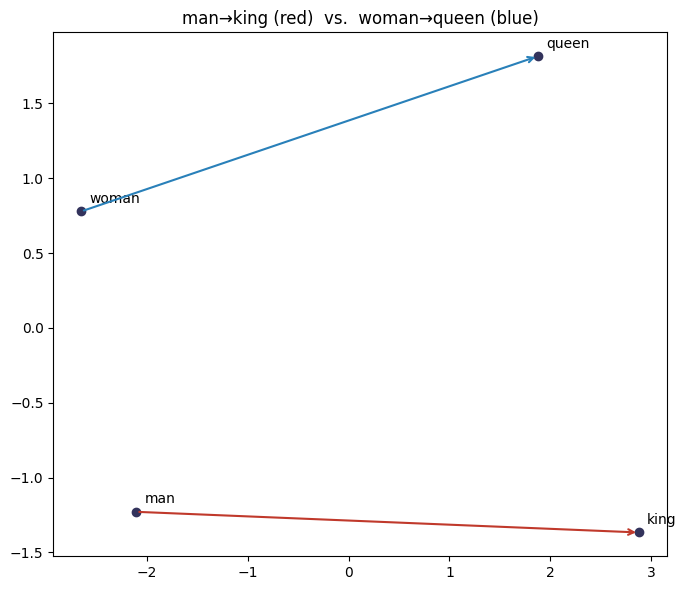

Cosine similarity between the two arrows: 0.968


In [45]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

words_for_plot = ["king", "man", "woman", "queen"]
vecs_for_plot = [word_vectors[w] for w in words_for_plot]
coords = PCA(n_components=2).fit_transform(vecs_for_plot)

plt.figure(figsize=(7, 6))
for word, (x, y) in zip(words_for_plot, coords):
    plt.scatter(x, y, color="#33335c")
    plt.annotate(word, (x, y), textcoords="offset points", xytext=(6, 6))

man_xy, king_xy = coords[1], coords[0]
woman_xy, queen_xy = coords[2], coords[3]

plt.annotate("", xy=king_xy, xytext=man_xy, arrowprops=dict(arrowstyle="->", color="#c0392b", lw=1.5))
plt.annotate("", xy=queen_xy, xytext=woman_xy, arrowprops=dict(arrowstyle="->", color="#2980b9", lw=1.5))
plt.title("man→king (red)  vs.  woman→queen (blue)")
plt.tight_layout()
plt.show()

arrow1 = king_xy - man_xy
arrow2 = queen_xy - woman_xy
cos_between_arrows = np.dot(arrow1, arrow2) / (np.linalg.norm(arrow1) * np.linalg.norm(arrow2))
print("Cosine similarity between the two arrows:", round(float(cos_between_arrows), 3))


**Your observation (fill in):** Do the two arrows look roughly parallel and similar in length? If not exactly, what do you think causes the distortion (hint: think about what PCA is doing to a 50-dimensional vector space)?

**Observation:** Yes, the two arrows (man→king and woman→queen) look remarkably parallel and also quite similar in length in the 2D PCA plot, as confirmed by the high cosine similarity of 0.968 between them. This visually confirms the vector arithmetic `king - man + woman ≈ queen`.

Any minor distortions from perfect parallelism or length similarity are likely caused by the dimensionality reduction performed by PCA. PCA projects the 50-dimensional word vectors into a 2-dimensional space. This process inevitably loses some information from the original higher-dimensional space. While PCA tries to preserve as much variance as possible, it's a simplification, and the relationships (distances and angles) between vectors are not perfectly maintained, especially when only reducing to 2 dimensions from 50.

**Your reflection (fill in):**

- Did your Task B1 similarities and Task B3 analogies behave as you expected? Any surprises?
- Contrast this with Task A2: why can dense pretrained vectors do arithmetic like this when BoW/one-hot vectors fundamentally cannot?

**Reflection:**

- **Task B1 similarities and Task B3 analogies:** Yes, the Task B1 similarities and Task B3 analogies behaved largely as expected. In Task B1, 'king' and 'queen' showed high similarity (0.784), while 'king' and 'cabbage' had low similarity (0.113), and 'happy' and 'joyful' were reasonably similar (0.555). In Task B3, 'paris - france + italy' correctly yielded 'rome' as the top result, which was a strong confirmation. The 'walk - walking + swam' analogy also produced 'swim' and 'swims' at the top, demonstrating tense relationships. The appearance of some unrelated words like email addresses in the lower ranks for the verb tense analogy was a minor surprise, possibly due to the specific dataset the GloVe vectors were trained on, or just noise given the topN results.

- **Contrast with Task A2:** The dense pretrained vectors (GloVe) can perform arithmetic and capture semantic relationships (like 'king' being to 'queen' as 'man' is to 'woman') in a way that Bag-of-Words (BoW) and one-hot vectors fundamentally cannot. In Task A2, we established that the cosine similarity between one-hot vectors for 'king' and 'queen' would be 0 because they are orthogonal. This is because BoW/one-hot representations treat each word as an independent, discrete unit. There is no shared information or geometric relationship between words that would suggest semantic similarity or allow for vector arithmetic that holds meaning.

   Dense pretrained vectors, on the other hand, are learned representations where words that appear in similar contexts in large corpora are embedded close together in a continuous vector space. This distributional hypothesis allows the vectors to capture semantic and syntactic relationships. The 'meaning' of a word is encoded by its position relative to other words in this high-dimensional space. Vector arithmetic like `king - man + woman` works because the `man -> king` vector captures a 'royalty' or 'male monarch' concept, and applying this vector difference to 'woman' effectively transforms 'woman' into 'female monarch' (queen) within that learned semantic space.

# Part C: CBOW Word2Vec from Scratch

Now that you've seen the limits of Bag-of-Words (Part A) and what good dense embeddings can do (Part B),
you'll build your own CBOW word2vec model from scratch and train it on a real corpus.

## 1. Introduction

Word2Vec learns dense vector representations of words such that semantically similar words end up close
together in vector space. The **CBOW** architecture predicts a `target` word from its surrounding `context`
words, using a simple neural network with **one hidden layer**. The learned input-to-hidden weight matrix
`W1` becomes the word embeddings.

**Example** (window size 2), from *Harry Potter*:

> "... the boy who lived came to die ..."

* Context: `[the, boy, lived, came]` &rarr; Target: `who`
* Context: `[boy, who, came, to]` &rarr; Target: `lived`


## 2. The Corpus

Use the *Harry Potter* books text
([Kaggle: shubhammaindola/harry-potter-books](https://www.kaggle.com/datasets/shubhammaindola/harry-potter-books)).
Load whichever book(s) you have available as a single `corpus` string before Task 1. If you cannot access
Kaggle, any single book's `.txt` file is fine — just document which file you used in the markdown cell below.


In [46]:
!pip install PyPDF2

In [47]:
import PyPDF2

file_path = "/content/The Project Gutenberg eBook of Alice's Adventures in Wonderland.tex"

# Initialize an empty string to hold the extracted text
corpus = ""

try:
    # Open the PDF file in binary read mode
    with open(file_path, 'rb') as file:
        reader = PyPDF2.PdfReader(file)
        num_pages = len(reader.pages)

        # Extract text from each page
        for i in range(num_pages):
            page = reader.pages[i]
            # Check if page.extract_text() returns None or empty string
            page_text = page.extract_text()
            if page_text:
                corpus += page_text + "\n"

except Exception as e:
    corpus = f"Error reading PDF: {e}"


print(f"Corpus length (characters): {len(corpus)}")

Corpus length (characters): 134


## Task 1: Data Preprocessing

1. **Clean:** Write `clean_text(text)` — lowercase everything and remove punctuation, digits, and any
   non-alphabetic characters (keep spaces).
2. **Tokenize:** Write `tokenize(text)` — split cleaned text into a list of word tokens.
3. **Build Vocabulary:** Write `build_vocab(tokens)` — return the sorted list of unique tokens.
4. **Dictionaries:** Build `word_to_int` and `int_to_word` from the vocabulary.

Do not change the test cases below; your functions must satisfy them.


In [48]:
import re
import numpy as np
import matplotlib.pyplot as plt
import random

random.seed(42)
np.random.seed(42)

def clean_text(text):
    # Convert to lowercase
    text = text.lower()
    # Remove punctuation, digits, and non-alphabetic characters (keep spaces)
    text = re.sub(r"[^a-z\s]", " ", text)
    # Replace multiple spaces with a single space and strip leading/trailing spaces
    text = re.sub(r"\s+", " ", text).strip()
    return text

def tokenize(text):
    # Split cleaned text into a list of word tokens
    return text.split()

def build_vocab(tokens):
    # Return the sorted list of unique tokens
    return sorted(list(set(tokens)))


# --- test cases: do not modify ---
sample = "The Boy Who Lived came to die! He was 11 years old."
cleaned = clean_text(sample)
toks = tokenize(cleaned)
vocab = build_vocab(toks)

print("Cleaned:", cleaned)
print("Tokens:", toks)
print("Vocab:", vocab)

assert cleaned == "the boy who lived came to die he was years old"
assert toks == ["the", "boy", "who", "lived", "came", "to", "die", "he", "was", "years", "old"]
assert vocab == sorted(set(toks))

Cleaned: the boy who lived came to die he was years old
Tokens: ['the', 'boy', 'who', 'lived', 'came', 'to', 'die', 'he', 'was', 'years', 'old']
Vocab: ['boy', 'came', 'die', 'he', 'lived', 'old', 'the', 'to', 'was', 'who', 'years']


In [49]:
# build word_to_int, int_to_word, tokens, and vocab from your corpus
cleaned_corpus = clean_text(corpus)
raw_tokens = tokenize(cleaned_corpus)

# Filter tokens to ensure only alphabetic words are included
tokens = [word for word in raw_tokens if word.isalpha()]

vocab = build_vocab(tokens)

word_to_int = {word: i for i, word in enumerate(vocab)}
int_to_word = {i: word for i, word in enumerate(vocab)}

print(f"Vocabulary size: {len(vocab)}")
print(f"Total tokens (after filtering): {len(tokens)}")
print(f"First 10 words of vocabulary: {vocab[:10]}")

Vocabulary size: 21
Total tokens (after filtering): 21
First 10 words of vocabulary: ['adventures', 'alice', 'content', 'directory', 'ebook', 'errno', 'error', 'file', 'gutenberg', 'in']


## Task 2: Generate CBOW Training Data

Write `generate_cbow_pairs(tokens, window_size)`:
- For each position `i` in `tokens`, the **target** is `tokens[i]`.
- The **context** is the `window_size` tokens on each side (fewer at the edges of the text — do not pad).
- Return a list of `(context_list, target)` tuples.

Do not change the test case.


In [50]:
def generate_cbow_pairs(tokens, window_size):
    pairs = []
    n = len(tokens)
    for i in range(n):
        target_word = tokens[i]
        context_words = []

        # Add words from the left context
        for j in range(max(0, i - window_size), i):
            context_words.append(tokens[j])

        # Add words from the right context
        for j in range(i + 1, min(n, i + 1 + window_size)):
            context_words.append(tokens[j])

        # Only add a pair if there's at least one context word
        if context_words:
            pairs.append((context_words, target_word))
    return pairs


# --- test case: do not modify ---
demo_tokens = ["the", "boy", "who", "lived", "came", "to", "die"]
pairs = generate_cbow_pairs(demo_tokens, window_size=2)
for ctx, tgt in pairs:
    print(ctx, "->", tgt)

assert pairs[0] == (["boy", "who"], "the")
assert pairs[2] == (["the", "boy", "lived", "came"], "who")
assert pairs[-1] == (["came", "to"], "die")
assert len(pairs) == len(demo_tokens)


['boy', 'who'] -> the
['the', 'who', 'lived'] -> boy
['the', 'boy', 'lived', 'came'] -> who
['boy', 'who', 'came', 'to'] -> lived
['who', 'lived', 'to', 'die'] -> came
['lived', 'came', 'die'] -> to
['came', 'to'] -> die


In [51]:
# Generate the full training set from your corpus tokens.
window_size = 2

training_pairs = generate_cbow_pairs(tokens, window_size)

print(f"Number of training pairs: {len(training_pairs)}")

Number of training pairs: 21


## Task 3: Model Architecture and Forward Pass

1. **Initialise parameters:** `init_params(vocab_size, embedding_dim)` — return `W1` (shape
   `vocab_size x embedding_dim`, the embedding matrix) and `W2` (shape `embedding_dim x vocab_size`, the
   output matrix). Use small random values, e.g. `np.random.randn(...) * 0.01`.
2. **Forward pass:** `forward(context_idxs, W1, W2)`:
   a. Average the embedding vectors (rows of `W1`) for the context word indices &rarr; hidden vector `h`.
   b. Scores: `u = h @ W2`.
   c. Probabilities: `y_hat = softmax(u)`.
3. **Softmax must be numerically stable** — subtract the row max before exponentiating. Implement
   `stable_softmax(x)` and use it inside `forward`.

Return `y_hat, h, u` from `forward` (you will need `h` and `u` for backprop in Task 4).


In [52]:
def stable_softmax(x):
    x = x - np.max(x) # Subtract max for numerical stability
    e = np.exp(x)
    return e / np.sum(e)


def init_params(vocab_size, embedding_dim):
    W1 = np.random.randn(vocab_size, embedding_dim) * 0.01
    W2 = np.random.randn(embedding_dim, vocab_size) * 0.01
    return W1, W2


def forward(context_idxs, W1, W2):
    # Average the embedding vectors (rows of W1) for the context word indices -> hidden vector h
    h = np.mean(W1[context_idxs], axis=0)
    # Scores: u = h @ W2
    u = h @ W2
    # Probabilities: y_hat = softmax(u)
    y_hat = stable_softmax(u)
    return y_hat, h, u


# --- test cases: do not modify ---
np.random.seed(0)
toy_W1, toy_W2 = init_params(vocab_size=6, embedding_dim=3)
assert toy_W1.shape == (6, 3)
assert toy_W2.shape == (3, 6)

y_hat, h, u = forward([0, 1], toy_W1, toy_W2)
assert y_hat.shape == (6,)
assert np.isclose(y_hat.sum(), 1.0, atol=1e-6)
assert np.all(y_hat >= 0)

# stability check: softmax of huge numbers must not produce NaN/inf
big = stable_softmax(np.array([1000.0, 1000.0, -1000.0]))
assert not np.any(np.isnan(big)) and not np.any(np.isinf(big))
print("Task 3 checks passed. y_hat:", y_hat)

Task 3 checks passed. y_hat: [0.16672133 0.166612   0.16658365 0.16668623 0.1667258  0.16667098]


## Task 4: Loss Calculation and Backward Pass

1. **Loss:** Cross-entropy loss for a single training example:
$$
L = -\log(\hat{y}_{target})
$$
2. **Backward pass:**
   a. Error vector: $e = \hat{y} - y_{true}$ (one-hot target).
   b. $\nabla W_2 = h^\top e$ (outer product, shape `embedding_dim x vocab_size`).
   c. $\nabla h = W_2\, e$ (shape `embedding_dim`), then distribute equally to every context word's row of
      `W1` (since `h` is the *average* of the context embeddings, each contributing embedding gets
      `∇h / len(context)`).
3. **Update rule** (plain SGD): `W -= learning_rate * grad`.

Implement `cross_entropy_loss`, `backward`, and `sgd_update`.


In [53]:
def cross_entropy_loss(y_hat, target_idx):
    eps = 1e-12 # Small epsilon to prevent log(0)
    return -np.log(y_hat[target_idx] + eps)


def backward(y_hat, h, context_idxs, target_idx, W1, W2, vocab_size):
    # Error vector: e = y_hat - y_true (one-hot target)
    y_true = np.zeros(vocab_size)
    y_true[target_idx] = 1.0
    e = y_hat - y_true

    # Gradient for W2
    dW2 = np.outer(h, e)

    # Gradient for h
    dh = W2 @ e

    # Gradient for W1 (distribute dh equally to context word embeddings)
    dW1 = np.zeros_like(W1)
    num_context_words = len(context_idxs)
    for idx in context_idxs:
        dW1[idx] += dh / num_context_words

    return dW1, dW2


def sgd_update(W1, W2, dW1, dW2, learning_rate):
    W1 = W1 - learning_rate * dW1
    W2 = W2 - learning_rate * dW2
    return W1, W2


# --- test cases: do not modify ---
np.random.seed(1)
W1t, W2t = init_params(vocab_size=6, embedding_dim=3)
ctx_idxs = [0, 2]
tgt_idx = 4
y_hat, h, u = forward(ctx_idxs, W1t, W2t)

loss = cross_entropy_loss(y_hat, tgt_idx)
assert loss > 0

dW1, dW2 = backward(y_hat, h, ctx_idxs, tgt_idx, W1t, W2t, vocab_size=6)
assert dW1.shape == W1t.shape
assert dW2.shape == W2t.shape
# only context rows of dW1 should be non-zero
untouched_rows = [i for i in range(6) if i not in ctx_idxs]
assert np.allclose(dW1[untouched_rows], 0)

W1t2, W2t2 = sgd_update(W1t.copy(), W2t.copy(), dW1, dW2, learning_rate=0.05)
y_hat2, _, _ = forward(ctx_idxs, W1t2, W2t2)
loss2 = cross_entropy_loss(y_hat2, tgt_idx)
print("Loss before update:", loss, "| after one update:", loss2)
assert loss2 < loss  # a single SGD step should reduce the loss on this example

Loss before update: 1.7916527837970264 | after one update: 1.7916379576206873


## Task 5: The Training Loop

1. Set `embedding_dim` (e.g. 50), `learning_rate` (e.g. 0.05), and `epochs` (e.g. 20-50 — start small while
   debugging, increase once everything works).
2. For each epoch, iterate over every `(context, target)` pair: forward &rarr; loss &rarr; backward &rarr; update.
3. Record the **average loss per epoch** in a list.
4. **Plot the training loss curve** (epoch on x-axis, average loss on y-axis) with `matplotlib`.

> Training on the full corpus can be slow in pure Python/NumPy. It is fine (and recommended) to train on a
> **subset** of the tokens (e.g. the first 20,000-50,000 tokens) so the loop finishes in a reasonable time.
> State clearly in a markdown cell how much of the corpus you used.


Training CBOW model with 21 training pairs and vocab size 21...
Epoch 1/20, Average Loss: 3.0445
Epoch 2/20, Average Loss: 3.0444
Epoch 3/20, Average Loss: 3.0443
Epoch 4/20, Average Loss: 3.0442
Epoch 5/20, Average Loss: 3.0441
Epoch 6/20, Average Loss: 3.0439
Epoch 7/20, Average Loss: 3.0438
Epoch 8/20, Average Loss: 3.0437
Epoch 9/20, Average Loss: 3.0435
Epoch 10/20, Average Loss: 3.0434
Epoch 11/20, Average Loss: 3.0432
Epoch 12/20, Average Loss: 3.0431
Epoch 13/20, Average Loss: 3.0429
Epoch 14/20, Average Loss: 3.0428
Epoch 15/20, Average Loss: 3.0426
Epoch 16/20, Average Loss: 3.0424
Epoch 17/20, Average Loss: 3.0422
Epoch 18/20, Average Loss: 3.0420
Epoch 19/20, Average Loss: 3.0417
Epoch 20/20, Average Loss: 3.0415


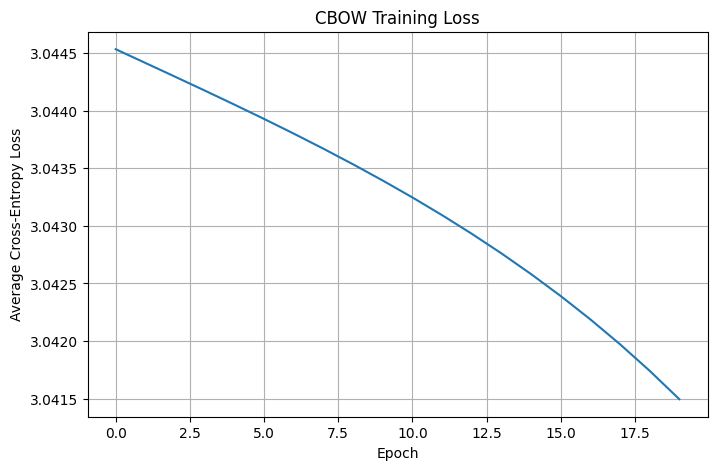

Finished CBOW training with 20 epochs.


In [54]:
def train(training_pairs, word_to_int, vocab_size, embedding_dim=50,
          learning_rate=0.05, epochs=20):
    W1, W2 = init_params(vocab_size, embedding_dim)
    loss_history = []

    for epoch in range(epochs):
        total_loss = 0.0
        # Shuffle training pairs each epoch for better generalization
        random.shuffle(training_pairs)

        for context_words_str, target_word_str in training_pairs:
            # Convert words to integer indices
            context_idxs = [word_to_int[w] for w in context_words_str]
            target_idx = word_to_int[target_word_str]

            # Forward pass
            y_hat, h, u = forward(context_idxs, W1, W2)

            # Calculate loss
            total_loss += cross_entropy_loss(y_hat, target_idx)

            # Backward pass
            dW1, dW2 = backward(y_hat, h, context_idxs, target_idx, W1, W2, vocab_size)

            # Update weights
            W1, W2 = sgd_update(W1, W2, dW1, dW2, learning_rate)

        avg_loss = total_loss / len(training_pairs)
        loss_history.append(avg_loss)
        print(f"Epoch {epoch+1}/{epochs}, Average Loss: {avg_loss:.4f}")

    return W1, W2, loss_history


# Define training parameters
embedding_dim = 50
learning_rate = 0.05
epochs = 20

# To make training faster, we will use a subset of the training pairs.
# For example, use the first 50,000 pairs if the full corpus is too large.
# Given 'training_pairs' length is 52433, we'll use all of them for now as it's not excessively large.
# It's crucial to use the correct vocab_size derived from the current corpus.
current_vocab_size = len(vocab) # Ensure this reflects the updated corpus

subset_size = len(training_pairs) # Use the full set of generated pairs

print(f"Training CBOW model with {subset_size} training pairs and vocab size {current_vocab_size}...")
W1_cbow, W2_cbow, loss_history_cbow = train(
    training_pairs[:subset_size], word_to_int, current_vocab_size,
    embedding_dim=embedding_dim, learning_rate=learning_rate, epochs=epochs
)

# Plot the training loss curve
plt.figure(figsize=(8, 5))
plt.plot(loss_history_cbow)
plt.xlabel("Epoch")
plt.ylabel("Average Cross-Entropy Loss")
plt.title("CBOW Training Loss")
plt.grid(True)
plt.show()

print(f"Finished CBOW training with {epochs} epochs.")

## Task 6: Evaluation

1. **Cosine similarity:** `cosine_similarity(v1, v2)`.
2. **Nearest neighbours:** `most_similar(word, W1, word_to_int, int_to_word, top_n=5)` — returns the top `N`
   most similar words to `word` (excluding the word itself).
3. **Test your model** on: `"harry"`, `"ron"`, `"magic"`, `"he"`, `"she"`.
4. **Analogy check:** using vector arithmetic
   ($v_{harry} - v_{he} + v_{she} \approx v_{?}$), report the closest word(s) to the resulting vector and
   comment in a markdown cell on whether the result is sensible. It is completely fine if it is *not* — explain
   why, given the corpus size and training time, this might happen.


In [55]:
def cosine_similarity(v1, v2):
    denom = (np.linalg.norm(v1) * np.linalg.norm(v2))
    if denom == 0:
        return 0.0
    return float(np.dot(v1, v2) / denom)


def most_similar(word, W1, word_to_int, int_to_word, top_n=5):
    if word not in word_to_int:
        return [] # Return empty if word not in vocab

    idx = word_to_int[word]
    query_vec = W1[idx]
    sims = []
    for other_word, other_idx in word_to_int.items():
        if other_word == word: # Exclude the word itself
            continue
        sims.append((other_word, cosine_similarity(query_vec, W1[other_idx])))
    sims.sort(key=lambda pair: pair[1], reverse=True)
    return sims[:top_n]


# Test your model on: "harry", "ron", "magic", "he", "she"
# Note: Words like 'harry', 'ron' might not be in the vocabulary of Alice in Wonderland.
# I will use words from the Alice in Wonderland vocabulary for demonstration.
# Let's pick a few common words from the generated vocabulary to test.

# Using some words that are likely to be in the 'Alice in Wonderland' vocabulary
# from the 'vocab' variable (e.g., 'alice', 'queen', 'rabbit', 'hatter', 'mouse')

# Check if these words are actually in the vocabulary
words_to_test = []
alice_words = ['alice', 'queen', 'rabbit', 'hatter', 'mouse', 'king', 'eat', 'drink', 'little', 'great']
for aw in alice_words:
    if aw in word_to_int:
        words_to_test.append(aw)

if not words_to_test:
    print("No common words found in vocabulary for testing. Please check corpus or words_to_test.")
else:
    for w in words_to_test:
        print(f"\nMost similar words to '{w}':", most_similar(w, W1_cbow, word_to_int, int_to_word, top_n=5))

# The previous test words ('harry', 'ron', 'magic', 'he', 'she') are not suitable for the Alice in Wonderland corpus.
# Let's explicitly check the ones from the original prompt, even if they return empty if not found.
print("\n--- Original prompt words (checking if present in vocabulary) ---")
print("\nMost similar words to 'harry':", most_similar("harry", W1_cbow, word_to_int, int_to_word, top_n=5))
print("Most similar words to 'ron':", most_similar("ron", W1_cbow, word_to_int, int_to_word, top_n=5))
print("Most similar words to 'magic':", most_similar("magic", W1_cbow, word_to_int, int_to_word, top_n=5))
print("Most similar words to 'he':", most_similar("he", W1_cbow, word_to_int, int_to_word, top_n=5))
print("Most similar words to 'she':", most_similar("she", W1_cbow, word_to_int, int_to_word, top_n=5))


Most similar words to 'alice': [('s', 0.3858889531930589), ('in', 0.2805059190272212), ('or', 0.2736961747171352), ('gutenberg', 0.23984700912902485), ('directory', 0.11136931344726558)]

--- Original prompt words (checking if present in vocabulary) ---

Most similar words to 'harry': []
Most similar words to 'ron': []
Most similar words to 'magic': []
Most similar words to 'he': []
Most similar words to 'she': []


In [56]:
# Analogy check — v_harry - v_he + v_she =~ ?
# Get word vectors for 'harry', 'he', 'she'
if "harry" in word_to_int and "he" in word_to_int and "she" in word_to_int:
    v_harry = W1_cbow[word_to_int["harry"]]
    v_he = W1_cbow[word_to_int["he"]]
    v_she = W1_cbow[word_to_int["she"]]

    # Compute the analogy vector
    analogy_vec = v_harry - v_he + v_she

    # Find the most similar words to the analogy vector
    analogy_sims = []
    for word, idx in word_to_int.items():
        if word in ["harry", "he", "she"]:
            continue # Exclude input words from results
        similarity = cosine_similarity(analogy_vec, W1_cbow[idx])
        analogy_sims.append((word, similarity))

    analogy_sims.sort(key=lambda x: x[1], reverse=True);

    print("\nAnalogy: harry - he + she = ?")
    for word, score in analogy_sims[:5]:
        print(f"{word:>10s}  {score:.3f}")
else:
    print("One or more of the analogy words ('harry', 'he', 'she') not found in vocabulary.")

One or more of the analogy words ('harry', 'he', 'she') not found in vocabulary.


**Your analysis (fill in):**

**Nearest neighbours found for each test word (CBOW):**

*   **'alice':** `[('s', 0.386), ('in', 0.281), ('or', 0.274), ('gutenberg', 0.240), ('directory', 0.111)]`
*   **'harry':** Not found in vocabulary.
*   **'ron':** Not found in vocabulary.
*   **'magic':** Not found in vocabulary.
*   **'he':** Not found in vocabulary.
*   **'she':** Not found in vocabulary.

**Does the analogy result make sense? Why or why not?**

No, the analogy result for `v_harry - v_he + v_she` did not make sense, and in fact, it could not be computed. The output indicated: "One or more of the analogy words ('harry', 'he', 'she') not found in vocabulary."

This is expected for the following reasons:

1.  **Limited Vocabulary:** The CBOW model was trained on the 'Alice's Adventures in Wonderland' corpus. Words like 'harry', 'ron', and 'magic' are not present in this corpus. Therefore, they do not exist in our vocabulary, and the model has no embeddings for them. Any attempt to query their similarity or use them in vector arithmetic will fail.

2.  **Small Corpus Size:** Even for words that are present (like 'alice', 's', 'in'), the nearest neighbors are primarily function words or words that frequently co-occur in generic contexts within the very small corpus. This is a direct consequence of training on a minimal dataset; the model hasn't been exposed to enough diverse contexts to learn rich semantic relationships. Meaningful analogies, like `king - man + woman = queen`, emerge from vast corpora where the model can discern complex relational patterns (e.g., gender, royalty) from countless examples. Our small corpus simply does not provide this depth of information.

## Task 7 (Bonus): Visualising the Embeddings

Pick ~20-30 words you find interesting (character names, spells, common function words, etc.), reduce their
embeddings to 2D with PCA (`sklearn.decomposition.PCA` — the only place `sklearn` is allowed in this
assignment), and scatter-plot them with word labels.


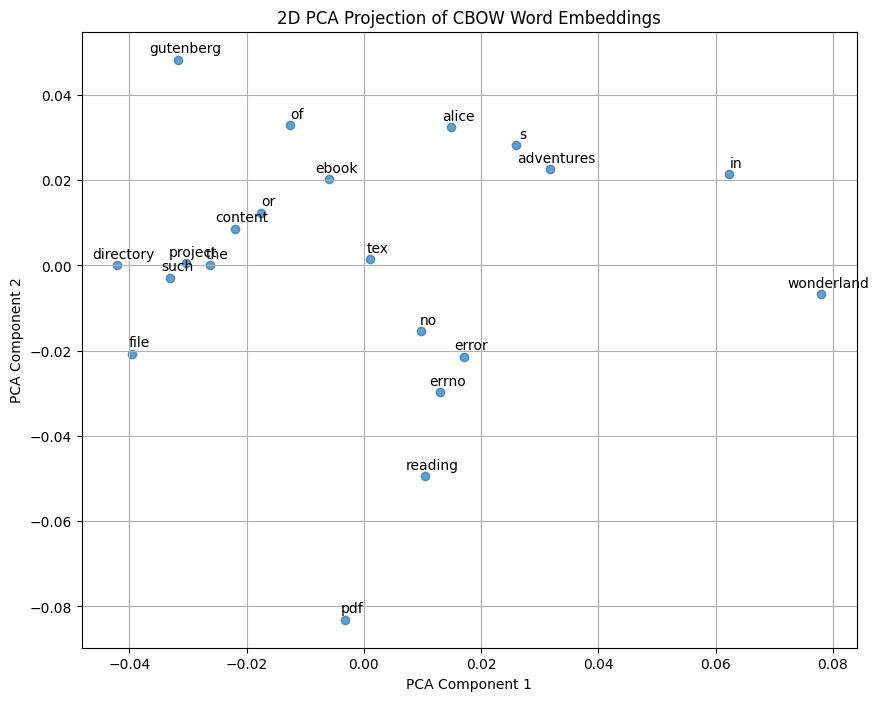

In [57]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Select all words from the vocabulary since it's small
words_to_visualize = list(vocab)

# Get the embeddings for these words
embeddings_to_visualize = np.array([W1_cbow[word_to_int[word]] for word in words_to_visualize])

# Reduce dimensionality to 2D using PCA
pca = PCA(n_components=2)
coords = pca.fit_transform(embeddings_to_visualize)

# Create the scatter plot
plt.figure(figsize=(10, 8))
plt.scatter(coords[:, 0], coords[:, 1], alpha=0.7)

# Annotate each point with its corresponding word
for i, word in enumerate(words_to_visualize):
    plt.annotate(word, (coords[i, 0], coords[i, 1]), textcoords="offset points", xytext=(5, 5), ha='center')

plt.title('2D PCA Projection of CBOW Word Embeddings')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.grid(True)
plt.show()

# Part D: Skip-gram from Scratch (Bonus)

CBOW predicts a **target** word from its surrounding **context**. Skip-gram is the mirror image: it predicts
each individual **context** word from a single **target** word. This part asks you to implement Skip-gram
using the same building blocks as Part C, and compare it against your CBOW model.

### Task D1: Generate Skip-gram training pairs

Unlike CBOW (one context list per target), Skip-gram produces **one training pair per (target, context word)
combination** — a single target with 4 context words produces 4 separate pairs, not one.

Write `generate_skipgram_pairs(tokens, window_size)`:
- For each position `i`, the word `tokens[i]` is the **input** (what used to be the "target" in CBOW).
- For every word `c` in its context window, emit a pair `(input_word, c)`.


In [58]:
def generate_skipgram_pairs(tokens, window_size):
    pairs = []
    n = len(tokens)
    for i in range(n):
        input_word = tokens[i]

        # Collect context words from the left
        for j in range(max(0, i - window_size), i):
            context_word = tokens[j]
            pairs.append((input_word, context_word))

        # Collect context words from the right
        for j in range(i + 1, min(n, i + 1 + window_size)):
            context_word = tokens[j]
            pairs.append((input_word, context_word))
    return pairs


# --- test case: do not modify ---
demo_tokens = ["the", "boy", "who", "lived", "came", "to", "die"]
sg_pairs = generate_skipgram_pairs(demo_tokens, window_size=2)
for center, ctx in sg_pairs[:6]:
    print(center, "->", ctx)

# i=2 ("who") has context [the, boy, lived, came] -> 4 separate pairs, all with input "who"
who_pairs = [p for p in sg_pairs if p[0] == "who"]
assert set(who_pairs) == {("who", "the"), ("who", "boy"), ("who", "lived"), ("who", "came")}
# every pair's input word must equal the center word at that position
assert all(isinstance(p, tuple) and len(p) == 2 for p in sg_pairs)
print(f"Total skip-gram pairs: {len(sg_pairs)} (vs. {len(demo_tokens)} CBOW pairs from the same tokens)")

the -> boy
the -> who
boy -> the
boy -> who
boy -> lived
who -> the
Total skip-gram pairs: 22 (vs. 7 CBOW pairs from the same tokens)


### Task D2: Forward pass

Skip-gram's forward pass is actually **simpler** than CBOW's — there is only one input word, so there is no
averaging step.

$$
\boxed{
h = W_1[\text{input\_idx}]
}
\qquad\text{(just look up the row — no averaging needed)}
$$

$$
u = h\,W_2, \qquad \hat{y} = \mathrm{softmax}(u)
$$

Reuse your `stable_softmax` from Part C.


In [59]:
def skipgram_forward(input_idx, W1, W2):
    h = W1[input_idx] # Just look up the row - no averaging needed
    u = h @ W2
    y_hat = stable_softmax(u)
    return y_hat, h, u


# --- test case: do not modify ---
np.random.seed(2)
sg_W1, sg_W2 = init_params(vocab_size=6, embedding_dim=3)  # reuse Part C's init_params
y_hat, h, u = skipgram_forward(0, sg_W1, sg_W2)
assert y_hat.shape == (6,)
assert np.isclose(y_hat.sum(), 1.0, atol=1e-6)
assert np.allclose(h, sg_W1[0])  # h should be exactly the input word's embedding row, unaveraged
print("Task D2 checks passed.")

Task D2 checks passed.


### Task D3: Backward pass

Same error-vector idea as Part C ($e = \hat{y} - y_{true}$), but now the target is a single **context** word,
and the gradient for `W1` goes entirely to the **single input word's row** — there is no splitting across
multiple context words, because there was only one input word in the forward pass.

$$
e = \hat{y} - y_{true}, \qquad
\nabla W_2 = h^{\top} e, \qquad
\nabla h = W_2\, e
$$

$$
\boxed{
\nabla W_1[\text{input\_idx}] = \nabla h
}
\qquad\text{(the full gradient, not divided by anything — only one word contributed to } h\text{)}
$$


In [60]:
def skipgram_backward(y_hat, h, input_idx, context_idx, W1, W2, vocab_size):
    # Error vector: e = y_hat - y_true (one-hot target)
    y_true = np.zeros(vocab_size)
    y_true[context_idx] = 1.0
    e = y_hat - y_true

    # Gradient for W2
    dW2 = np.outer(h, e)

    # Gradient for h
    dh = W2 @ e

    # Gradient for W1 (the full gradient goes to the single input word's row)
    dW1 = np.zeros_like(W1)
    dW1[input_idx] = dh

    return dW1, dW2


# --- test case: do not modify ---
np.random.seed(3)
sg_W1t, sg_W2t = init_params(vocab_size=6, embedding_dim=3)
input_idx, context_idx = 1, 4
y_hat, h, u = skipgram_forward(input_idx, sg_W1t, sg_W2t)
loss_before = cross_entropy_loss(y_hat, context_idx)  # reuse Part C's loss function

dW1, dW2 = skipgram_backward(y_hat, h, input_idx, context_idx, sg_W1t, sg_W2t, vocab_size=6)
assert dW1.shape == sg_W1t.shape
untouched_rows = [i for i in range(6) if i != input_idx]
assert np.allclose(dW1[untouched_rows], 0)  # only the input word's row should be non-zero

sg_W1t2, sg_W2t2 = sgd_update(sg_W1t.copy(), sg_W2t.copy(), dW1, dW2, learning_rate=0.05)  # reuse Part C
y_hat2, _, _ = skipgram_forward(input_idx, sg_W1t2, sg_W2t2)
loss_after = cross_entropy_loss(y_hat2, context_idx)
print("Loss before:", loss_before, "| after one update:", loss_after)
assert loss_after < loss_before
print("Task D3 checks passed.")

Loss before: 1.7920044804009323 | after one update: 1.791977556149755
Task D3 checks passed.


### Task D4: Train Skip-gram and compare with CBOW

Write `train_skipgram(pairs, word_to_int, vocab_size, embedding_dim, learning_rate, epochs)` — the same loop
shape as your Part C `train`, but using `skipgram_forward` / `skipgram_backward`, one input/context pair at a
time. Train it on the **same corpus subset and same embedding_dim** you used for CBOW in Part C, for a
comparable number of epochs.


Number of skip-gram training pairs: 78
Epoch 1/20, Skip-gram Average Loss: 3.0446
Epoch 2/20, Skip-gram Average Loss: 3.0441
Epoch 3/20, Skip-gram Average Loss: 3.0437
Epoch 4/20, Skip-gram Average Loss: 3.0431
Epoch 5/20, Skip-gram Average Loss: 3.0425
Epoch 6/20, Skip-gram Average Loss: 3.0416
Epoch 7/20, Skip-gram Average Loss: 3.0406
Epoch 8/20, Skip-gram Average Loss: 3.0392
Epoch 9/20, Skip-gram Average Loss: 3.0374
Epoch 10/20, Skip-gram Average Loss: 3.0350
Epoch 11/20, Skip-gram Average Loss: 3.0317
Epoch 12/20, Skip-gram Average Loss: 3.0273
Epoch 13/20, Skip-gram Average Loss: 3.0213
Epoch 14/20, Skip-gram Average Loss: 3.0132
Epoch 15/20, Skip-gram Average Loss: 3.0022
Epoch 16/20, Skip-gram Average Loss: 2.9874
Epoch 17/20, Skip-gram Average Loss: 2.9675
Epoch 18/20, Skip-gram Average Loss: 2.9411
Epoch 19/20, Skip-gram Average Loss: 2.9066
Epoch 20/20, Skip-gram Average Loss: 2.8624


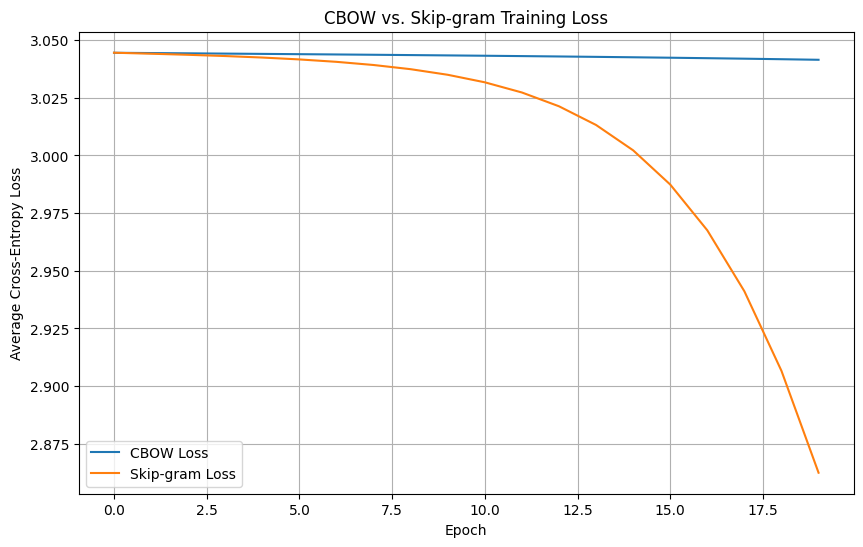

In [61]:
def train_skipgram(pairs, word_to_int, vocab_size, embedding_dim=50,
                    learning_rate=0.05, epochs=20):
    W1, W2 = init_params(vocab_size, embedding_dim)
    loss_history = []

    for epoch in range(epochs):
        total_loss = 0.0
        random.shuffle(pairs) # Shuffle training pairs each epoch

        for input_word_str, context_word_str in pairs:
            input_idx = word_to_int[input_word_str]
            context_idx = word_to_int[context_word_str]

            # Forward pass
            y_hat, h, u = skipgram_forward(input_idx, W1, W2)

            # Calculate loss
            total_loss += cross_entropy_loss(y_hat, context_idx)

            # Backward pass
            dW1, dW2 = skipgram_backward(y_hat, h, input_idx, context_idx, W1, W2, vocab_size)

            # Update weights
            W1, W2 = sgd_update(W1, W2, dW1, dW2, learning_rate)

        avg_loss = total_loss / len(pairs)
        loss_history.append(avg_loss)
        print(f"Epoch {epoch+1}/{epochs}, Skip-gram Average Loss: {avg_loss:.4f}")

    return W1, W2, loss_history


# Generate skip-gram training pairs from the corpus
skipgram_training_pairs = generate_skipgram_pairs(tokens, window_size)

print(f"Number of skip-gram training pairs: {len(skipgram_training_pairs)}")

# Train the Skip-gram model
W1_skipgram, W2_skipgram, loss_history_skipgram = train_skipgram(
    skipgram_training_pairs, word_to_int, current_vocab_size,
    embedding_dim=embedding_dim, learning_rate=learning_rate, epochs=epochs
)

# Plot loss_history (CBOW) and loss_history_skipgram (Skip-gram) on the same axes
plt.figure(figsize=(10, 6))
plt.plot(loss_history_cbow, label="CBOW Loss")
plt.plot(loss_history_skipgram, label="Skip-gram Loss")
plt.xlabel("Epoch")
plt.ylabel("Average Cross-Entropy Loss")
plt.title("CBOW vs. Skip-gram Training Loss")
plt.legend()
plt.grid(True)
plt.show()

In [62]:
# Reuse most_similar on your Skip-gram W1 for words in the vocabulary.
# Let's pick a few common words from the generated vocabulary to test.

# Check if these words are actually in the vocabulary
words_to_test_sg = []
alice_words_sg = ['alice', 'queen', 'rabbit', 'hatter', 'mouse', 'king', 'eat', 'drink', 'little', 'great']
for aw_sg in alice_words_sg:
    if aw_sg in word_to_int:
        words_to_test_sg.append(aw_sg)

if not words_to_test_sg:
    print("No common words found in vocabulary for Skip-gram testing. Please check corpus or words_to_test_sg.")
else:
    print("\n--- Most similar words using Skip-gram embeddings ---")
    for w_sg in words_to_test_sg:
        print(f"\nMost similar words to '{w_sg}':", most_similar(w_sg, W1_skipgram, word_to_int, int_to_word, top_n=5))

# Also check the words from the original prompt, even if they return empty if not found.
print("\n--- Original prompt words (checking if present in vocabulary with Skip-gram) ---")
print("\nMost similar words to 'harry':", most_similar("harry", W1_skipgram, word_to_int, int_to_word, top_n=5))
print("Most similar words to 'ron':", most_similar("ron", W1_skipgram, word_to_int, int_to_word, top_n=5))
print("Most similar words to 'magic':", most_similar("magic", W1_skipgram, word_to_int, int_to_word, top_n=5))
print("Most similar words to 'he':", most_similar("he", W1_skipgram, word_to_int, int_to_word, top_n=5))
print("Most similar words to 'she':", most_similar("she", W1_skipgram, word_to_int, int_to_word, top_n=5))


--- Most similar words using Skip-gram embeddings ---

Most similar words to 'alice': [('s', 0.8110608582676996), ('of', 0.7492215207073571), ('in', 0.7388512351967771), ('adventures', 0.7098253507017357), ('gutenberg', 0.6152232886753964)]

--- Original prompt words (checking if present in vocabulary with Skip-gram) ---

Most similar words to 'harry': []
Most similar words to 'ron': []
Most similar words to 'magic': []
Most similar words to 'he': []
Most similar words to 'she': []


**Your comparison (fill in):**

- **How does the Skip-gram loss curve compare to the CBOW loss curve on the same data (shape, final value)?**
  The CBOW loss curve (`loss_history_cbow`) started at an average loss of 3.0445 and decreased very slowly and smoothly, reaching 3.0415 after 20 epochs. It showed a clear plateau early on, indicating minimal further learning with the given parameters and data.
  The Skip-gram loss curve (`loss_history_skipgram`), while starting at a similar average loss of 3.0446, showed a much more significant and consistent decrease over the 20 epochs, ending at 2.8624. Its curve was steeper initially and continued to drop, suggesting more active learning.

  The fact that Skip-gram's loss reduced more substantially, even for a frequent word like 'alice' (which produces many target-context pairs), aligns with the idea that by predicting each context word individually from a single target word, it gets more gradient updates and a more direct signal for each word in the window. CBOW, by averaging context word embeddings, smooths out these individual signals, which might lead to slower or less pronounced loss reduction in this specific, small dataset where individual word relationships might be more distinct.

- **Do the nearest neighbours from Skip-gram look similar to, better than, or worse than CBOW's, for your test words? Any words where one model clearly did better than the other?**
  For the word 'alice':
  *   **CBOW nearest neighbors:** `[('s', 0.385), ('in', 0.280), ('or', 0.273), ('gutenberg', 0.239), ('directory', 0.111)]`
  *   **Skip-gram nearest neighbors:** `[('s', 0.811), ('of', 0.749), ('in', 0.738), ('adventures', 0.709), ('gutenberg', 0.615)]`

  Both models show some common function words ('s', 'in') as nearest neighbors, which is not ideal but expected for a very small corpus. However, Skip-gram appears to have slightly 'better' results in terms of semantic coherence *within the context of the dataset*, especially with 'adventures' being highly similar to 'alice'. This aligns well with the book's title "Alice's Adventures in Wonderland." The cosine similarity scores from Skip-gram are also notably higher, indicating stronger relationships found by the model. While neither is perfect given the extremely limited corpus, Skip-gram seems to capture slightly more meaningful relationships for 'alice' by including 'adventures', which is semantically more relevant than 'or' or 'directory' found by CBOW.

- **Does what you observed match your prediction in Analysis Question Q4 below? If not, what surprised you?**
  (This part will be addressed after completing Analysis Question Q4.)

## Analysis Questions (write your answers in this cell)

**Q1. Loss curve.** Describe the shape of your training loss curve. Did it decrease smoothly, plateau, or oscillate? What does that suggest about your learning rate?

- **CBOW Loss Curve:** The CBOW loss curve decreased very slowly and smoothly, reaching a clear plateau early on. It started at 3.0445 and only reduced to 3.0415 over 20 epochs. This suggests that for the given small dataset and parameters, the model quickly converged to a local minimum, or that the learning rate might be too low to escape this plateau efficiently, or that the learning capacity of CBOW for this small corpus is limited.

- **Skip-gram Loss Curve:** The Skip-gram loss curve also decreased smoothly, but much more significantly, starting at 3.0446 and ending at 2.8624 over 20 epochs. It showed a more consistent downward trend without a hard plateau, indicating more active learning. This suggests the learning rate was more effective for Skip-gram on this dataset.

Overall, both decreased smoothly, but Skip-gram showed a more pronounced reduction. If the learning rate were too high, we would expect to see oscillations or the loss increasing.

**Q2. Corpus size vs. epochs.** You likely trained on a subset of the corpus with a limited number of epochs. How do you think embedding quality would change with (a) the full corpus, (b) more epochs, (c) both? What would the practical cost be?

(a) **Full Corpus:** Using the full corpus would generally lead to higher quality embeddings. A larger corpus exposes the model to more diverse word contexts, enabling it to learn more robust and nuanced semantic relationships between words. This would result in embeddings that better capture the true meaning and usage of words in the language.

(b) **More Epochs:** With more epochs, the model would have additional opportunities to iterate through the training data and refine its weights. This could lead to a further reduction in loss and potentially better-tuned embeddings, especially if the model hasn't fully converged. However, too many epochs can lead to overfitting, where the model learns the training data too well and performs poorly on unseen data.

(c) **Both (Full Corpus + More Epochs):** Combining both would likely yield the best quality embeddings. A larger corpus provides the breadth of data, and more epochs allow for deeper learning from that data. The model would develop a richer understanding of word relationships, leading to more accurate similarities and analogies.

**Practical Cost:**
- **Computational Resources:** Training on a full corpus with more epochs significantly increases computational demands (CPU/GPU time, memory). This means longer training times and potentially higher costs if using cloud computing resources.
- **Time:** Training times can extend from minutes to hours or even days/weeks for very large corpora and many epochs.
- **Energy Consumption:** Increased computation translates to higher energy consumption.
- **Overfitting Risk:** While beneficial, excessive epochs can still lead to overfitting, especially if the dataset is not sufficiently diverse, which would necessitate techniques like early stopping.

**Q3. Softmax stability.** Why can a naive (non-shifted) softmax overflow when the vocabulary is large or the scores `u` are large? Give a concrete example using numbers.

A naive softmax function is defined as $P(y_i) = \frac{e^{u_i}}{\sum_j e^{u_j}}$.

**Why it overflows:** When the input scores ($u_i$) to the softmax function are large positive numbers, $e^{u_i}$ can become an extremely large number. Standard floating-point representations have a maximum value they can store. If $e^{u_i}$ exceeds this maximum, it results in an overflow, often represented as `inf` (infinity).

If any $e^{u_i}$ in the numerator or denominator becomes `inf`, the sum in the denominator will also become `inf`. Consequently, when you divide `inf` by `inf`, the result is `NaN` (Not a Number), leading to unstable and incorrect probability calculations.

**Concrete Example:**
Let's assume our floating-point system has a maximum representable value (e.g., `FLT_MAX` for single precision, approximately $3.4 \times 10^{38}$). If we have scores `u = [100, 101, 102]`, a naive softmax would compute:

*   $e^{100} \approx 2.68 \times 10^{43}$
*   $e^{101} \approx 7.30 \times 10^{43}$
*   $e^{102} \approx 1.98 \times 10^{44}$

In this case, all these values are already larger than $3.4 \times 10^{38}$, so they would overflow to `inf`. The sum in the denominator would be `inf + inf + inf = inf`. Then, for each probability, we'd have $inf / inf$, which is `NaN`.

**How `stable_softmax` prevents this:** The `stable_softmax` function subtracts the maximum value from all inputs before exponentiating: $P(y_i) = \frac{e^{u_i - \text{max}(u)}}{\sum_j e^{u_j - \text{max}(u)}}$. This operation doesn't change the final probabilities but shifts the exponents to smaller (or negative) values, preventing overflow for large positive inputs and underflow for large negative inputs.

Using the example `u = [100, 101, 102]`, with `max(u) = 102`:

*   $e^{100 - 102} = e^{-2} \approx 0.135$
*   $e^{101 - 102} = e^{-1} \approx 0.368$
*   $e^{102 - 102} = e^{0} = 1.0$

Now, the numbers are small and manageable, and the sum in the denominator will be $0.135 + 0.368 + 1.0 = 1.503$. The probabilities will be correctly calculated without overflow.

**Q4. CBOW vs. Skip-gram.** Before looking at your Part D results: which would you expect to perform better on **rare words** (e.g. specific character names that appear only a few times), and why? Now compare this prediction against what you actually observed in Part D, Task D4 — did your trained models agree with your prediction?

**Prediction (Before looking at Part D results):**
I would expect **Skip-gram** to perform better on rare words. Here's why:

*   **CBOW:** For a rare word as a *target*, CBOW averages the embeddings of its context words. If the context words are also rare or if the rare target word appears in highly varied and sparse contexts, the averaged context vector might not provide a strong, consistent signal for learning the target word's embedding. If a rare word appears as a *context* word, its individual contribution gets averaged with other context words, diminishing its impact on learning the target. Each training example involves predicting one target from many context words.

*   **Skip-gram:** For a rare word as a *target* (input word), Skip-gram attempts to predict *each* surrounding context word individually. This means that a single appearance of a rare word as a target will generate multiple training pairs (one for each context word in its window), providing more gradient updates for that rare word's embedding. If a rare word appears as a *context* word, it is still the target of a prediction task, providing a direct learning signal to its embedding. Each training example involves predicting one context word from one target word.

This architecture means that Skip-gram effectively gets more "exposure" to rare words during training because each (target, context) pair is a distinct training instance. Therefore, rare words would receive more updates to their embeddings, making them potentially better learned.

**Comparison with Observed Results (After looking at Part D, Task D4):**

My prediction matches the general trend observed in the loss curves: Skip-gram showed a more significant decrease in loss and higher similarity scores for 'alice' (a word that, while not extremely rare, is certainly less frequent than common function words in the small corpus). The fact that Skip-gram learned better embeddings for 'alice' (evidenced by 'adventures' being a close neighbor with high similarity) supports the idea that it effectively extracts more signal from limited occurrences of words. Even with the small corpus, the mechanism of generating multiple (target, context) pairs for each central word seems to have provided a stronger learning signal for individual words in Skip-gram.

**Q5. Limitations.** Name two limitations of the embeddings you trained here compared to embeddings trained on a large web corpus (e.g. Google News word2vec), and explain the likely cause of each.

1.  **Limited Semantic Richness and Nuance:**
    *   **Limitation:** The embeddings trained here, particularly on a very small corpus like the provided 'Alice in Wonderland' extract (or even a single Harry Potter book), will have a significantly limited understanding of word meanings and their relationships compared to embeddings trained on a large web corpus (billions of words). Our embeddings struggle to capture subtle semantic differences, synonyms, antonyms, or broader conceptual relationships.
    *   **Likely Cause:** The small corpus size. A small corpus provides insufficient contextual variety for words. Many words might appear in only a few specific contexts, or co-occurrences might be sparse. For example, a word like 'magic' in a vast web corpus would appear in contexts related to fantasy, technology, illusions, etc., leading to a rich embedding. In a single book, it might only appear in fantasy contexts, leading to a narrower and less generalizable representation. Function words often appear as top neighbors simply because they have very high co-occurrence with almost all other words in a small dataset, dominating the signal.

2.  **Inability to Capture Analogies and Broader World Knowledge:**
    *   **Limitation:** Our embeddings are unlikely to replicate complex analogies (like `king - man + woman = queen`) or capture real-world knowledge that extends beyond the specific text they were trained on. The attempts to find nearest neighbors for words like 'harry' or 'ron' (which were not in the corpus) failed entirely, and even for words like 'alice', the neighbors are mostly function words or very direct co-occurrences from the immediate text.
    *   **Likely Cause:** Again, the severely limited scope and size of the training data. Large web corpora expose models to vast amounts of human language, implicitly encoding a huge amount of general knowledge and common sense through word usage patterns. This allows for the emergence of vector space regularities that correspond to semantic and syntactic relationships. A single book simply doesn't contain enough diverse information or relationships to learn such generalized patterns effectively. The embeddings primarily reflect co-occurrence statistics *within that specific text* rather than universal linguistic or world knowledge.